# InfoDengue Dataset Exploration
Load the preprocessed parquet file and inspect columns.

In [1]:
import pandas as pd
from utils.config import PROJECT_ROOT



In [2]:
DATA_SET = "infodengue_capitals_subsetBR"

# Load the parquet dataset
df = pd.read_parquet(PROJECT_ROOT / "data" / "raw" / f"{DATA_SET}.parquet")
print(f"Shape: {df.shape}")
print(f"\nColumns ({len(df.columns)}):\n")
for col in df.columns:
    print(f"  - {col} ({df[col].dtype})")

Shape: (3340, 33)

Columns (33):

  - data_iniSE (object)
  - SE (int64)
  - casos_est (float64)
  - casos_est_min (int64)
  - casos_est_max (float64)
  - casos (int64)
  - p_rt1 (float64)
  - p_inc100k (float64)
  - Localidade_id (int64)
  - nivel (int64)
  - id (int64)
  - versao_modelo (object)
  - tweet (float64)
  - Rt (float64)
  - pop (float64)
  - tempmin (float64)
  - umidmax (float64)
  - receptivo (int64)
  - transmissao (float64)
  - nivel_inc (int64)
  - umidmed (float64)
  - umidmin (float64)
  - tempmed (float64)
  - tempmax (float64)
  - casprov (float64)
  - casprov_est (float64)
  - casprov_est_min (float64)
  - casprov_est_max (float64)
  - casconf (float64)
  - notif_accum_year (int64)
  - city_name (object)
  - state (object)
  - region (object)


In [3]:
display(df)

,data_iniSE,SE,casos_est,casos_est_min,casos_est_max,casos,p_rt1,p_inc100k,Localidade_id,nivel,...,tempmax,casprov,casprov_est,casprov_est_min,casprov_est_max,casconf,notif_accum_year,city_name,state,region
0,2025-12-28,202553,0.0,0,2.0,0,0.000000,0.000000,0,1,...,30.771240,0.0,NaN,NaN,NaN,NaN,144914,Vitória,ES,Southeast
1,2025-12-21,202552,0.0,0,1.0,0,0.000000,0.000000,0,1,...,28.081571,0.0,NaN,NaN,NaN,NaN,144914,Vitória,ES,Southeast
2,2025-12-14,202551,0.0,0,2.0,0,0.000000,0.000000,0,1,...,27.432457,0.0,NaN,NaN,NaN,NaN,144914,Vitória,ES,Southeast
3,2025-12-07,202550,2.0,2,4.0,2,0.000000,0.602800,0,1,...,28.940243,2.0,NaN,NaN,NaN,NaN,144914,Vitória,ES,Southeast
4,2025-11-30,202549,75.0,75,77.0,75,0.085194,22.605000,0,1,...,26.351029,75.0,NaN,NaN,NaN,NaN,144914,Vitória,ES,Southeast
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3335,2010-01-31,201005,247.0,247,247.0,247,0.000000,2.004019,0,2,...,32.428571,103.0,NaN,NaN,NaN,NaN,2060527,São Paulo,SP,Southeast
3336,2010-01-24,201004,203.0,203,203.0,203,0.000000,1.647028,0,2,...,26.428571,75.0,NaN,NaN,NaN,NaN,2060527,São Paulo,SP,Southeast
3337,2010-01-17,201003,168.0,168,168.0,168,0.000000,1.363058,0,2,...,28.000000,43.0,NaN,NaN,NaN,NaN,2060527,São Paulo,SP,Southeast
3338,2010-01-10,201002,144.0,144,144.0,144,0.000000,1.168335,0,1,...,28.571429,46.0,NaN,NaN,NaN,NaN,2060527,São Paulo,SP,Southeast


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Parse date column and get unique cities
df["data_iniSE"] = pd.to_datetime(df["data_iniSE"])
cities = df["city_name"].unique()
print(f"Cities ({len(cities)}): {cities.tolist()}")

Cities (4): ['Vitória', 'Belo Horizonte', 'Rio de Janeiro', 'São Paulo']


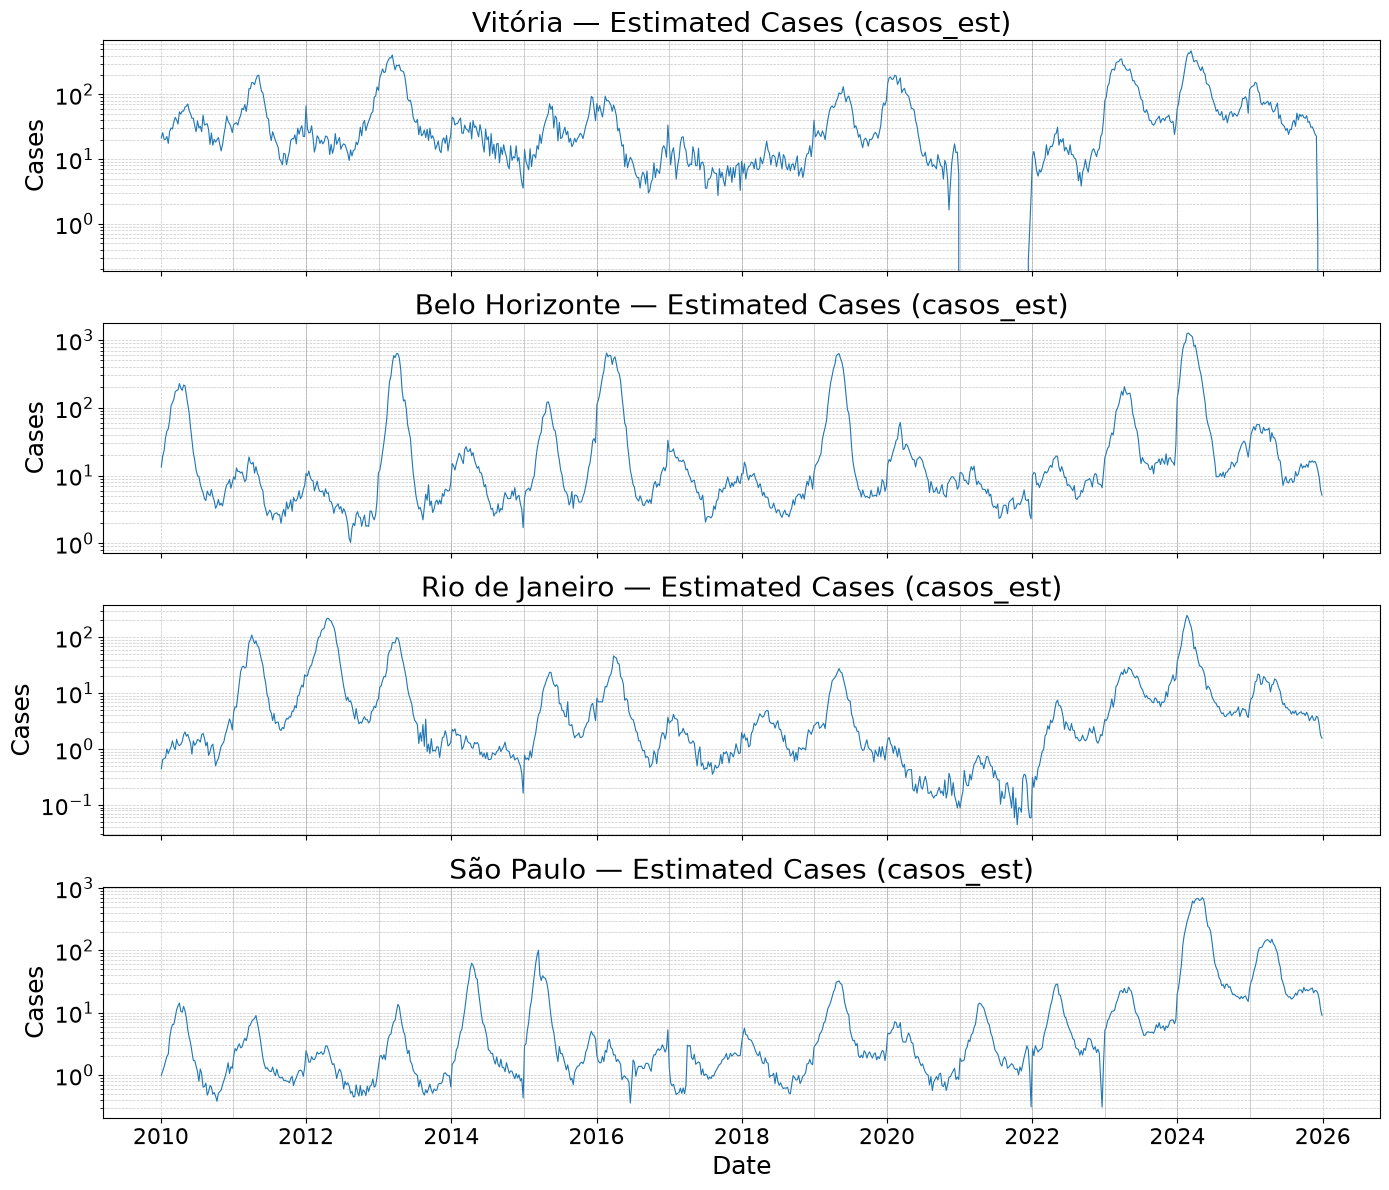

In [5]:
fig, axes = plt.subplots(len(cities), 1, figsize=(14, 3 * len(cities)), sharex=True)

FS = 18

for ax, city in zip(axes, cities):
    city_df = df[df["city_name"] == city].sort_values("data_iniSE")
    ax.plot(city_df["data_iniSE"], city_df["p_inc100k"], linewidth=0.8)
    ax.set_title(f"{city} — Estimated Cases (casos_est)", fontsize=FS+2)
    ax.set_ylabel("Cases", fontsize=FS)
    ax.set_yscale("log")
    ax.tick_params(axis="both", labelsize=FS-2)
    ax.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.7)
    
    # Add vertical lines at year boundaries
    years = pd.date_range(start=city_df["data_iniSE"].min(), end=city_df["data_iniSE"].max(), freq="YS")
    for year in years:
        ax.axvline(x=year, color="gray", linestyle="-", linewidth=0.5, alpha=0.5)

plt.xlabel("Date", fontsize=FS)
plt.tight_layout()
plt.show()

### Correlation Matrix (Weekly) per City
Correlation between the weekly log incidence, its value in the previous week and the climate variables, shown in a 2x2 grid.

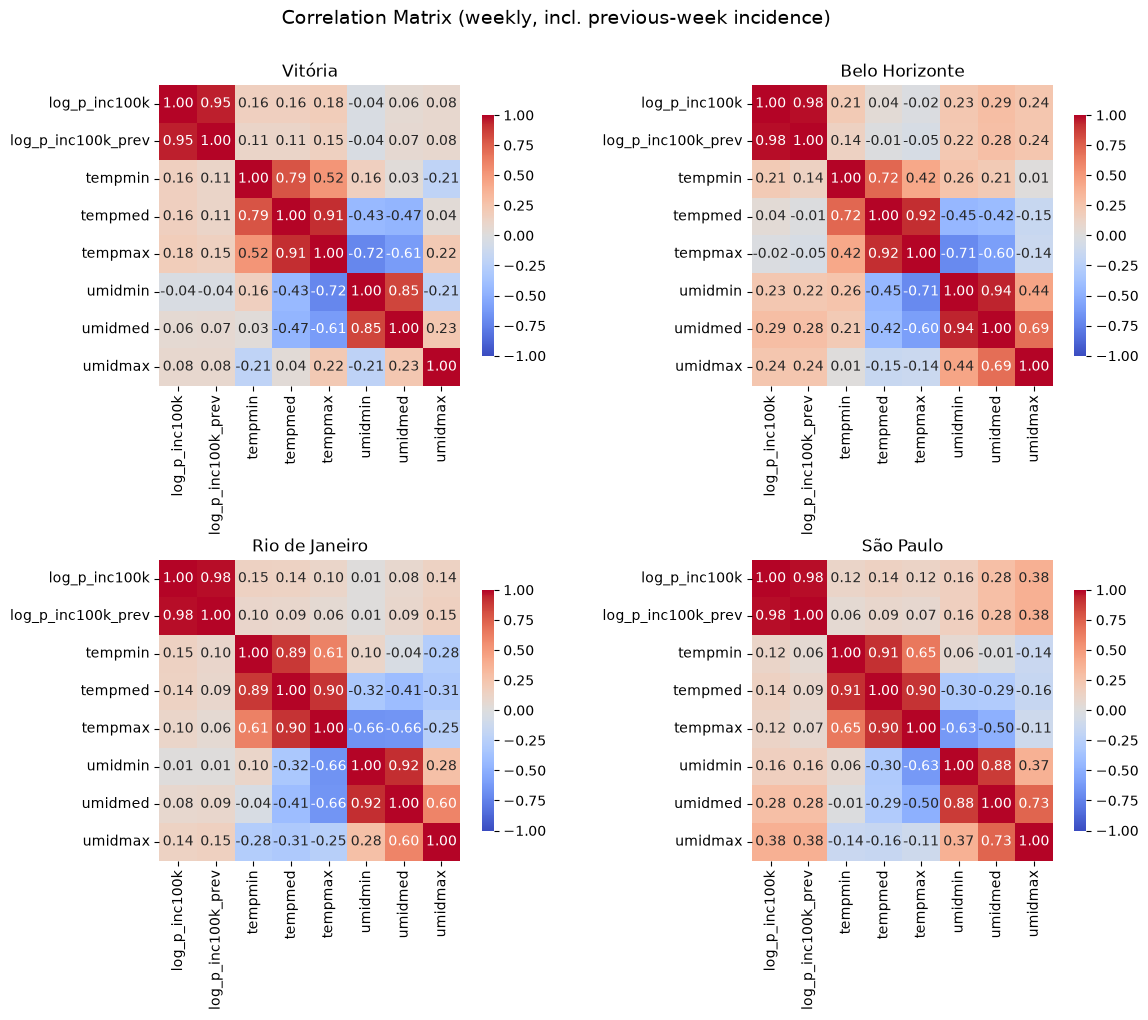

In [6]:
# Weekly log incidence and its previous-week value per city (zero weeks are reporting gaps)
df = df.sort_values(["city_name", "data_iniSE"])
df["log_p_inc100k"] = np.log(df["p_inc100k"].where(df["p_inc100k"] > 0))
df["log_p_inc100k_prev"] = df.groupby("city_name")["log_p_inc100k"].shift(1)

corr_cols = ["log_p_inc100k", "log_p_inc100k_prev", "tempmin", "tempmed", "tempmax", "umidmin", "umidmed", "umidmax"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, city in zip(axes.flatten(), cities):
    corr = df.loc[df["city_name"] == city, corr_cols].dropna().corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
                ax=ax, square=True, cbar_kws={"shrink": 0.8})
    ax.set_title(city)

plt.suptitle("Correlation Matrix (weekly, incl. previous-week incidence)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Lagged Effect of the Weather on Epidemic Growth
Correlation between the weekly growth rate of the incidence, log x(t+1) - log x(t), and the climate anomaly (deviation from the city's mean for that epidemiological week) k weeks before the predicted week t+1, averaged over the cities. Weather acts on dengue with a delay: mosquito development and the incubation of the virus in mosquito and human take several weeks.

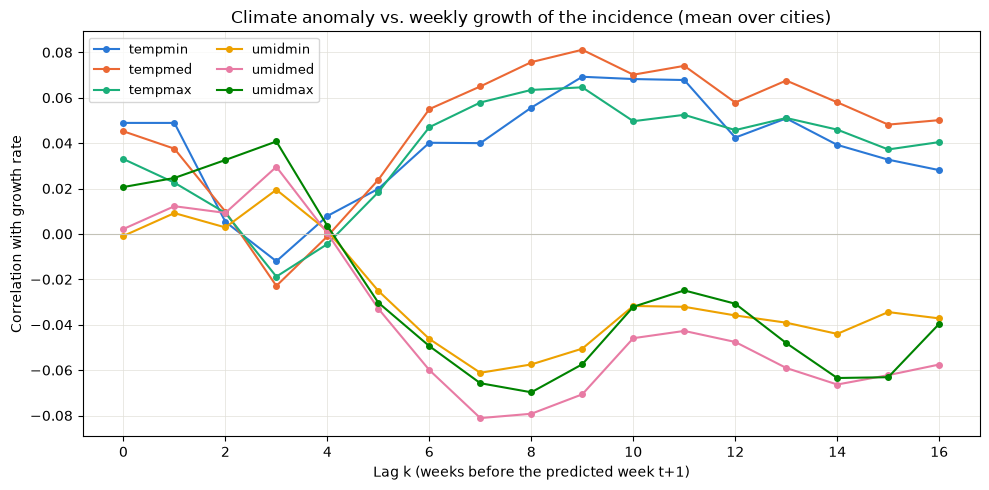

In [7]:
# Growth rate from week t to t+1, smoothed over 4 weeks to damp reporting noise
df["epi_week"] = df["SE"] % 100
df["growth"] = df.groupby("city_name")["log_p_inc100k"].transform(
    lambda s: (s.shift(-1) - s).rolling(4, center=True, min_periods=3).mean()
)

climate_vars = ["tempmin", "tempmed", "tempmax", "umidmin", "umidmed", "umidmax"]
city_rows = df.groupby("city_name").groups.values()
records = []
for var in climate_vars:
    anomaly = df[var] - df.groupby(["city_name", "epi_week"])[var].transform("mean")
    for k in range(17):  # k = 0: weather of the predicted week t+1
        lagged = anomaly.groupby(df["city_name"]).shift(k - 1)
        corr = np.mean([df.loc[rows, "growth"].corr(lagged.loc[rows]) for rows in city_rows])
        records.append({"variable": var, "lag": k, "corr": corr})
lag_corr = pd.DataFrame(records)

colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
fig, ax = plt.subplots(figsize=(10, 5))
for var, color in zip(climate_vars, colors):
    var_corr = lag_corr[lag_corr["variable"] == var]
    ax.plot(var_corr["lag"], var_corr["corr"], marker="o", markersize=4, linewidth=1.5, color=color, label=var)
ax.axhline(0, color="#c3c2b7", linewidth=0.8)
ax.set_xlabel("Lag k (weeks before the predicted week t+1)")
ax.set_ylabel("Correlation with growth rate")
ax.set_title("Climate anomaly vs. weekly growth of the incidence (mean over cities)")
ax.grid(True, color="#e1e0d9", linewidth=0.5)
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

### Estimated vs Reported Cases (with confidence interval)
Compare `casos_est`, `casos_est_min`, `casos_est_max`, and `casos` for each city within a configurable time window.

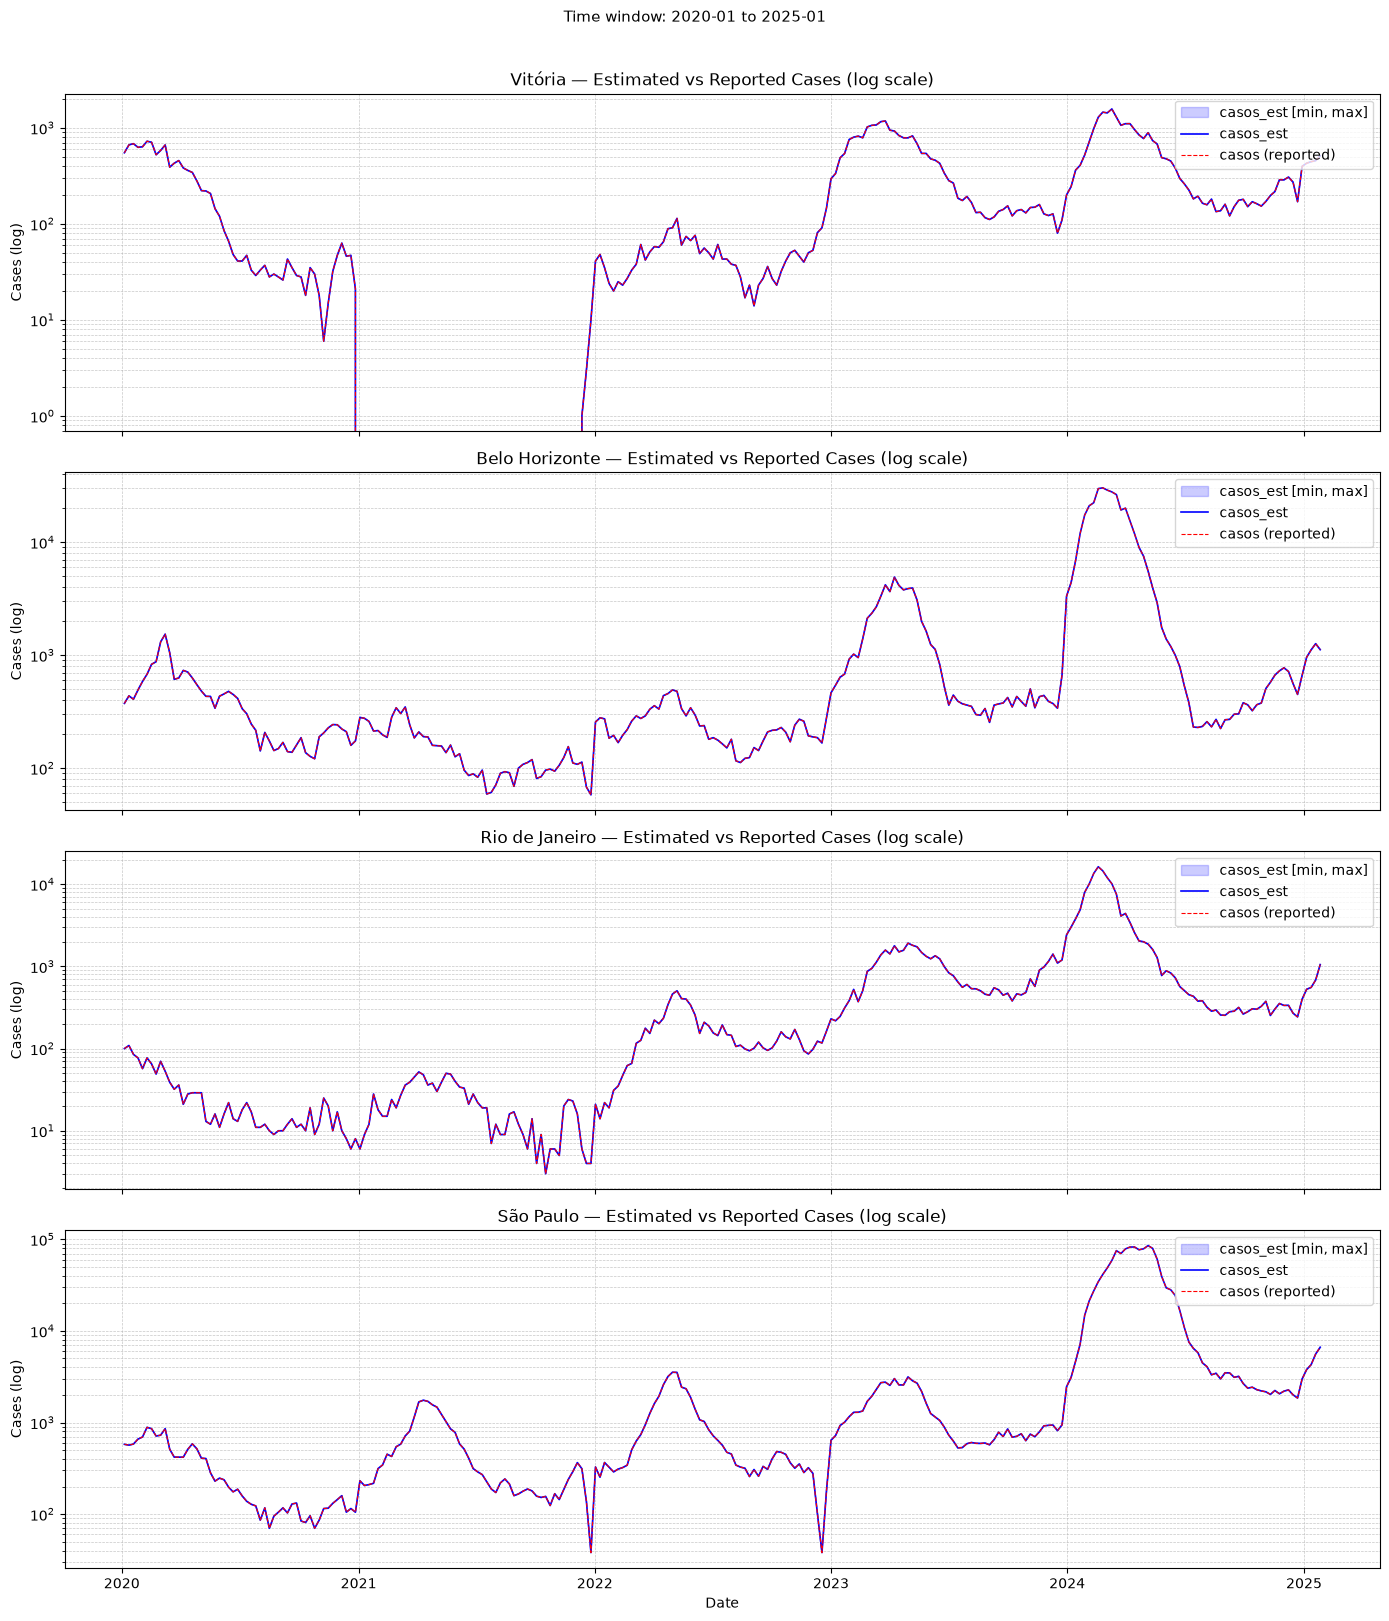

In [8]:
# Specify time window (format: "YYYY-MM") or set to None for full range
time_window_start = "2017-10"  # e.g. "2024-01"
time_window_end = "2018-01"    # e.g. "2025-06"
time_window_start = "2020-01"  # e.g. "2024-01"
time_window_end = "2025-01"    # e.g. "2025-06"

# Filter by time window
df_filtered = df.copy()
if time_window_start:
    df_filtered = df_filtered[df_filtered["data_iniSE"] >= f"{time_window_start}-01"]
if time_window_end:
    df_filtered = df_filtered[df_filtered["data_iniSE"] <= f"{time_window_end}-31"]

fig, axes = plt.subplots(len(cities), 1, figsize=(14, 4 * len(cities)), sharex=True)

for ax, city in zip(axes, cities):
    city_df = df_filtered[df_filtered["city_name"] == city].sort_values("data_iniSE")
    
    # Confidence interval band
    ax.fill_between(city_df["data_iniSE"], city_df["casos_est_min"], city_df["casos_est_max"],
                    alpha=0.2, color="blue", label="casos_est [min, max]")
    # Estimated cases
    ax.plot(city_df["data_iniSE"], city_df["casos_est"], color="blue", linewidth=1.2, label="casos_est")
    # Reported cases
    ax.plot(city_df["data_iniSE"], city_df["casos"], color="red", linewidth=0.8, linestyle="--", label="casos (reported)")
    
    ax.set_yscale("log")
    ax.set_title(f"{city} — Estimated vs Reported Cases (log scale)")
    ax.set_ylabel("Cases (log)")
    ax.legend(loc="upper right")
    ax.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.7)

plt.xlabel("Date")
window_label = f"{time_window_start or 'start'} to {time_window_end or 'end'}"
plt.suptitle(f"Time window: {window_label}", y=1.01, fontsize=11)
plt.tight_layout()
plt.show()

### Incidence Rate vs Climate (Temperature & Humidity)
Plot `p_inc100k` (left y-axis) alongside `tempmed` and `umidmed` (right y-axis) for each city.

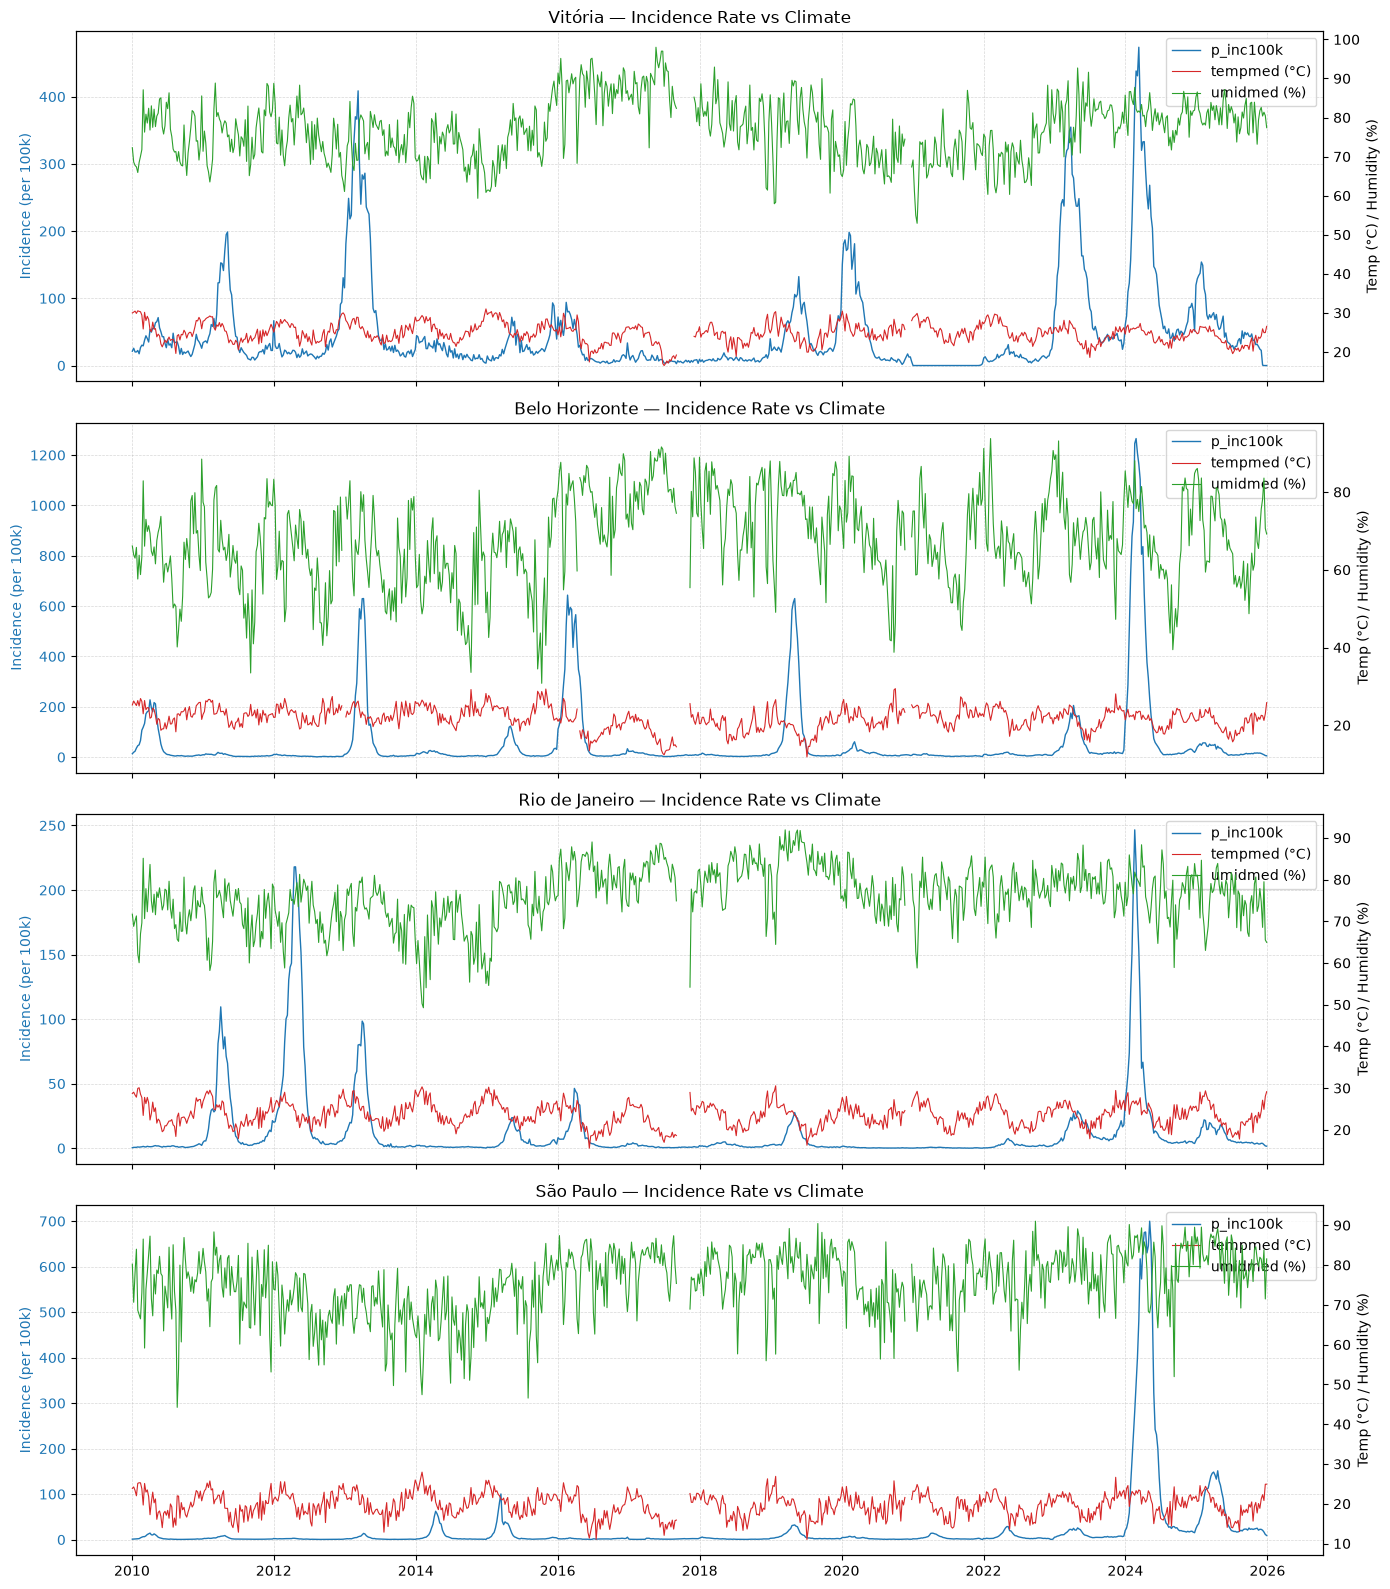

In [9]:
fig, axes = plt.subplots(len(cities), 1, figsize=(14, 4 * len(cities)), sharex=True)

for ax, city in zip(axes, cities):
    city_df = df[df["city_name"] == city].sort_values("data_iniSE")
    
    # Left y-axis: incidence rate
    color_inc = "tab:blue"
    ax.plot(city_df["data_iniSE"], city_df["p_inc100k"], color=color_inc, linewidth=1.0, label="p_inc100k")
    ax.set_ylabel("Incidence (per 100k)", color=color_inc)
    ax.tick_params(axis="y", labelcolor=color_inc)
    ax.set_title(f"{city} — Incidence Rate vs Climate")
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.5)
    
    # Right y-axis: temperature and humidity
    ax2 = ax.twinx()
    ax2.plot(city_df["data_iniSE"], city_df["tempmed"], color="tab:red", linewidth=0.8, label="tempmed (°C)")
    ax2.plot(city_df["data_iniSE"], city_df["umidmed"], color="tab:green", linewidth=0.8, label="umidmed (%)")
    ax2.set_ylabel("Temp (°C) / Humidity (%)")
    ax2.tick_params(axis="y")
    
    # Combined legend
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.xlabel("Date")
plt.tight_layout()
plt.show()

### Incidence Rate vs Climate Receptivity
Plot `p_inc100k` (left y-axis) alongside `receptivo` (right y-axis) for each city.

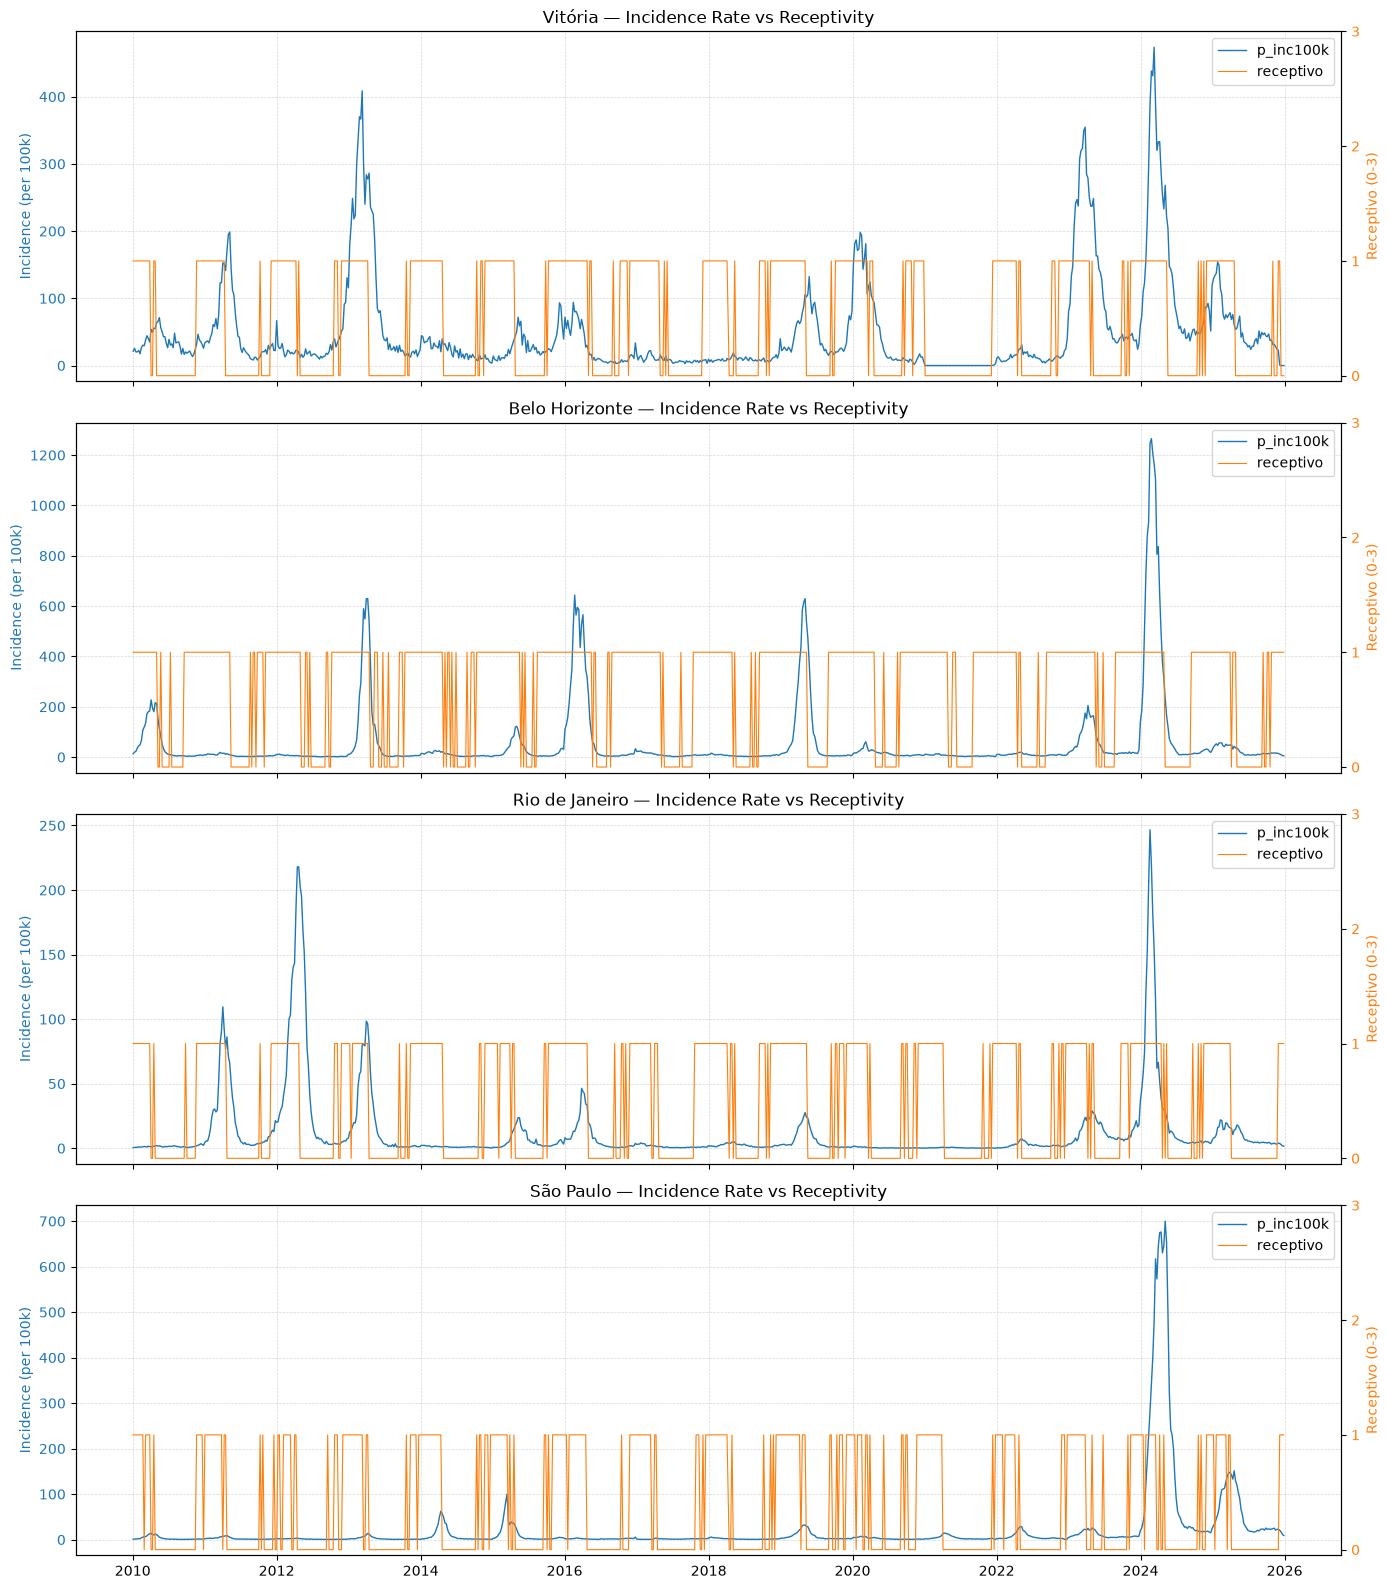

In [10]:
fig, axes = plt.subplots(len(cities), 1, figsize=(14, 4 * len(cities)), sharex=True)

for ax, city in zip(axes, cities):
    city_df = df[df["city_name"] == city].sort_values("data_iniSE")
    
    # Left y-axis: incidence rate
    color_inc = "tab:blue"
    ax.plot(city_df["data_iniSE"], city_df["p_inc100k"], color=color_inc, linewidth=1.0, label="p_inc100k")
    ax.set_ylabel("Incidence (per 100k)", color=color_inc)
    ax.tick_params(axis="y", labelcolor=color_inc)
    ax.set_title(f"{city} — Incidence Rate vs Receptivity")
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.5)
    
    # Right y-axis: receptivo
    ax2 = ax.twinx()
    ax2.plot(city_df["data_iniSE"], city_df["receptivo"], color="tab:orange", linewidth=0.8, label="receptivo")
    ax2.set_ylabel("Receptivo (0-3)", color="tab:orange")
    ax2.tick_params(axis="y", labelcolor="tab:orange")
    ax2.set_yticks([0, 1, 2, 3])
    
    # Combined legend
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.xlabel("Date")
plt.tight_layout()
plt.show()

### Incidence Rate vs Transmission Evidence
Plot `p_inc100k` (left y-axis) alongside `transmissao` (right y-axis) for each city.

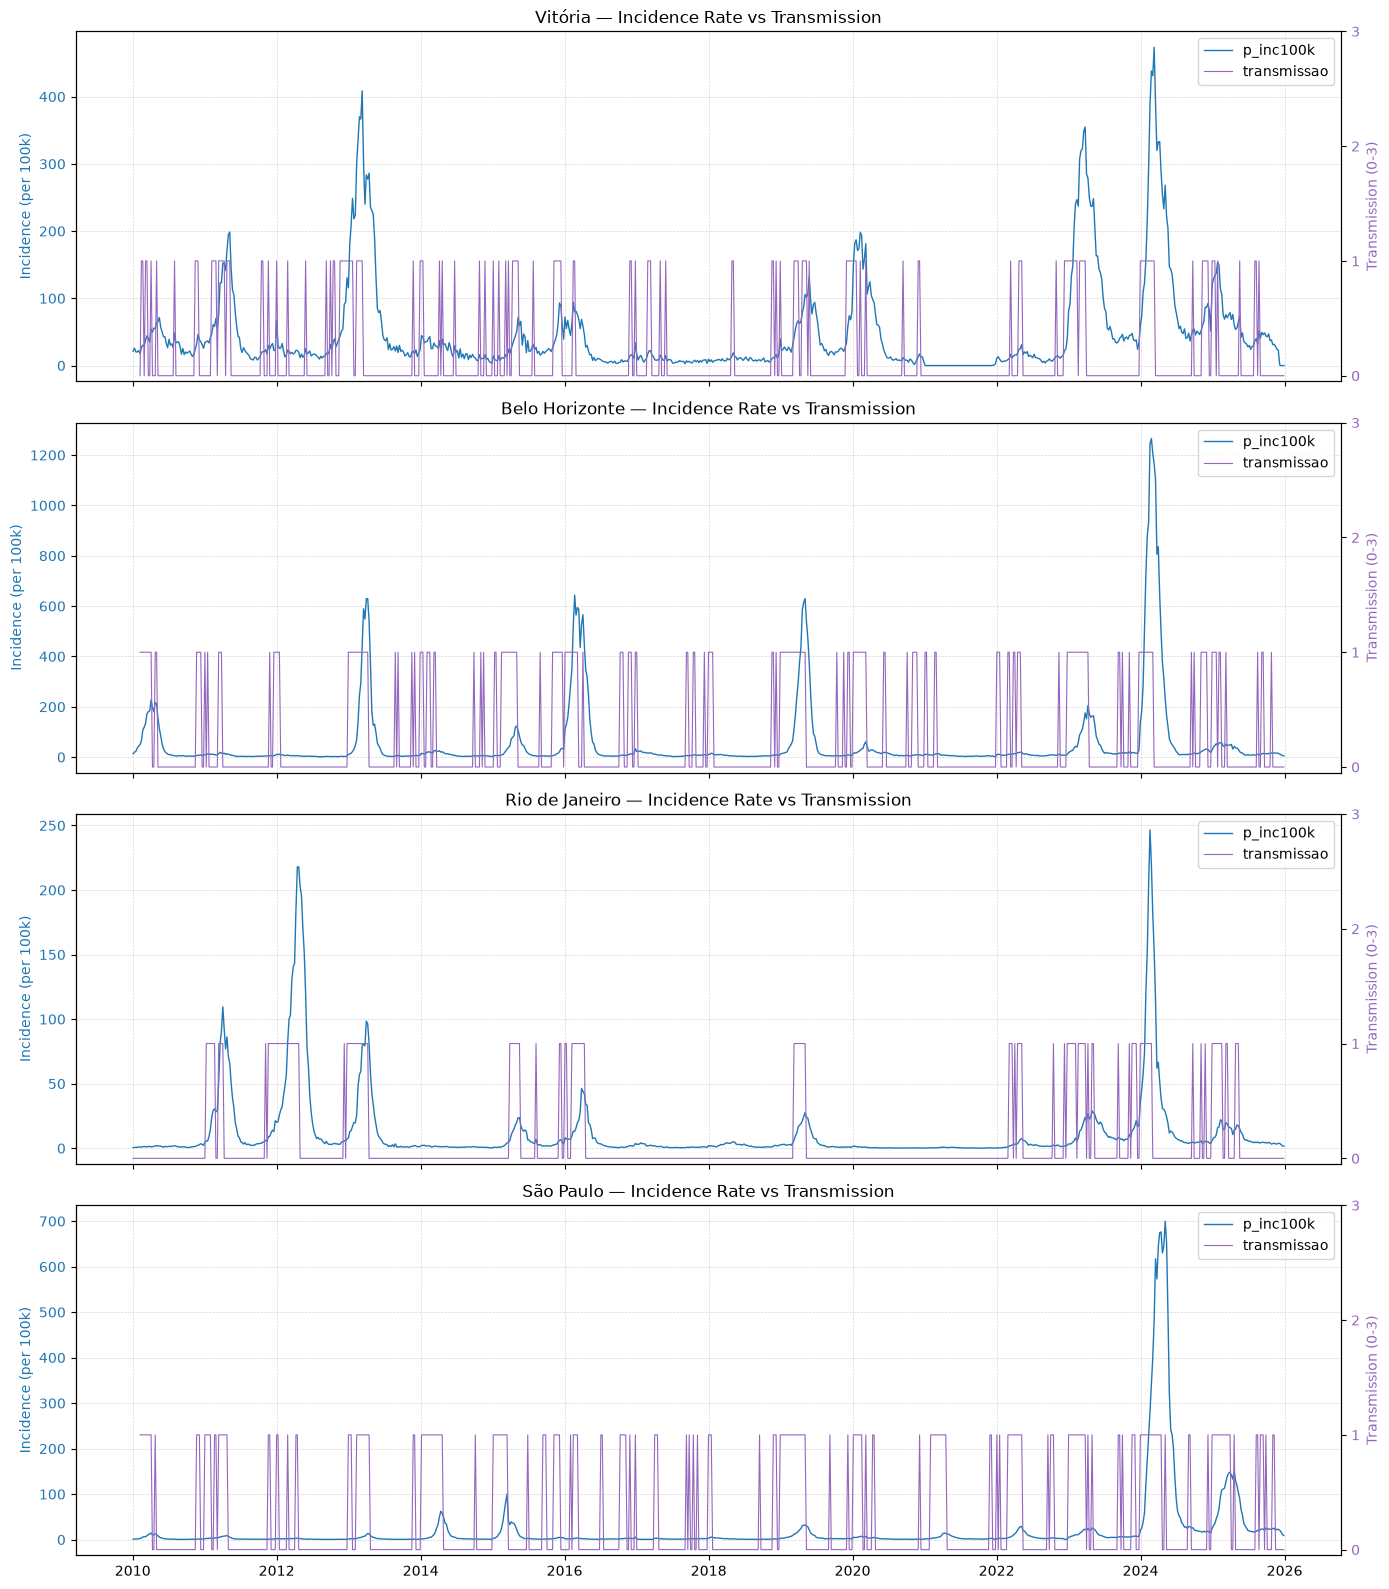

In [11]:
fig, axes = plt.subplots(len(cities), 1, figsize=(14, 4 * len(cities)), sharex=True)

for ax, city in zip(axes, cities):
    city_df = df[df["city_name"] == city].sort_values("data_iniSE")
    
    # Left y-axis: incidence rate
    color_inc = "tab:blue"
    ax.plot(city_df["data_iniSE"], city_df["p_inc100k"], color=color_inc, linewidth=1.0, label="p_inc100k")
    ax.set_ylabel("Incidence (per 100k)", color=color_inc)
    ax.tick_params(axis="y", labelcolor=color_inc)
    ax.set_title(f"{city} — Incidence Rate vs Transmission")
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.5)
    
    # Right y-axis: transmissao
    ax2 = ax.twinx()
    ax2.plot(city_df["data_iniSE"], city_df["transmissao"], color="tab:purple", linewidth=0.8, label="transmissao")
    ax2.set_ylabel("Transmission (0-3)", color="tab:purple")
    ax2.tick_params(axis="y", labelcolor="tab:purple")
    ax2.set_yticks([0, 1, 2, 3])
    
    # Combined legend
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.xlabel("Date")
plt.tight_layout()
plt.show()

### Incidence Rate vs Epidemic Threshold Level
Plot `p_inc100k` (left y-axis) alongside `nivel_inc` (right y-axis) for each city.

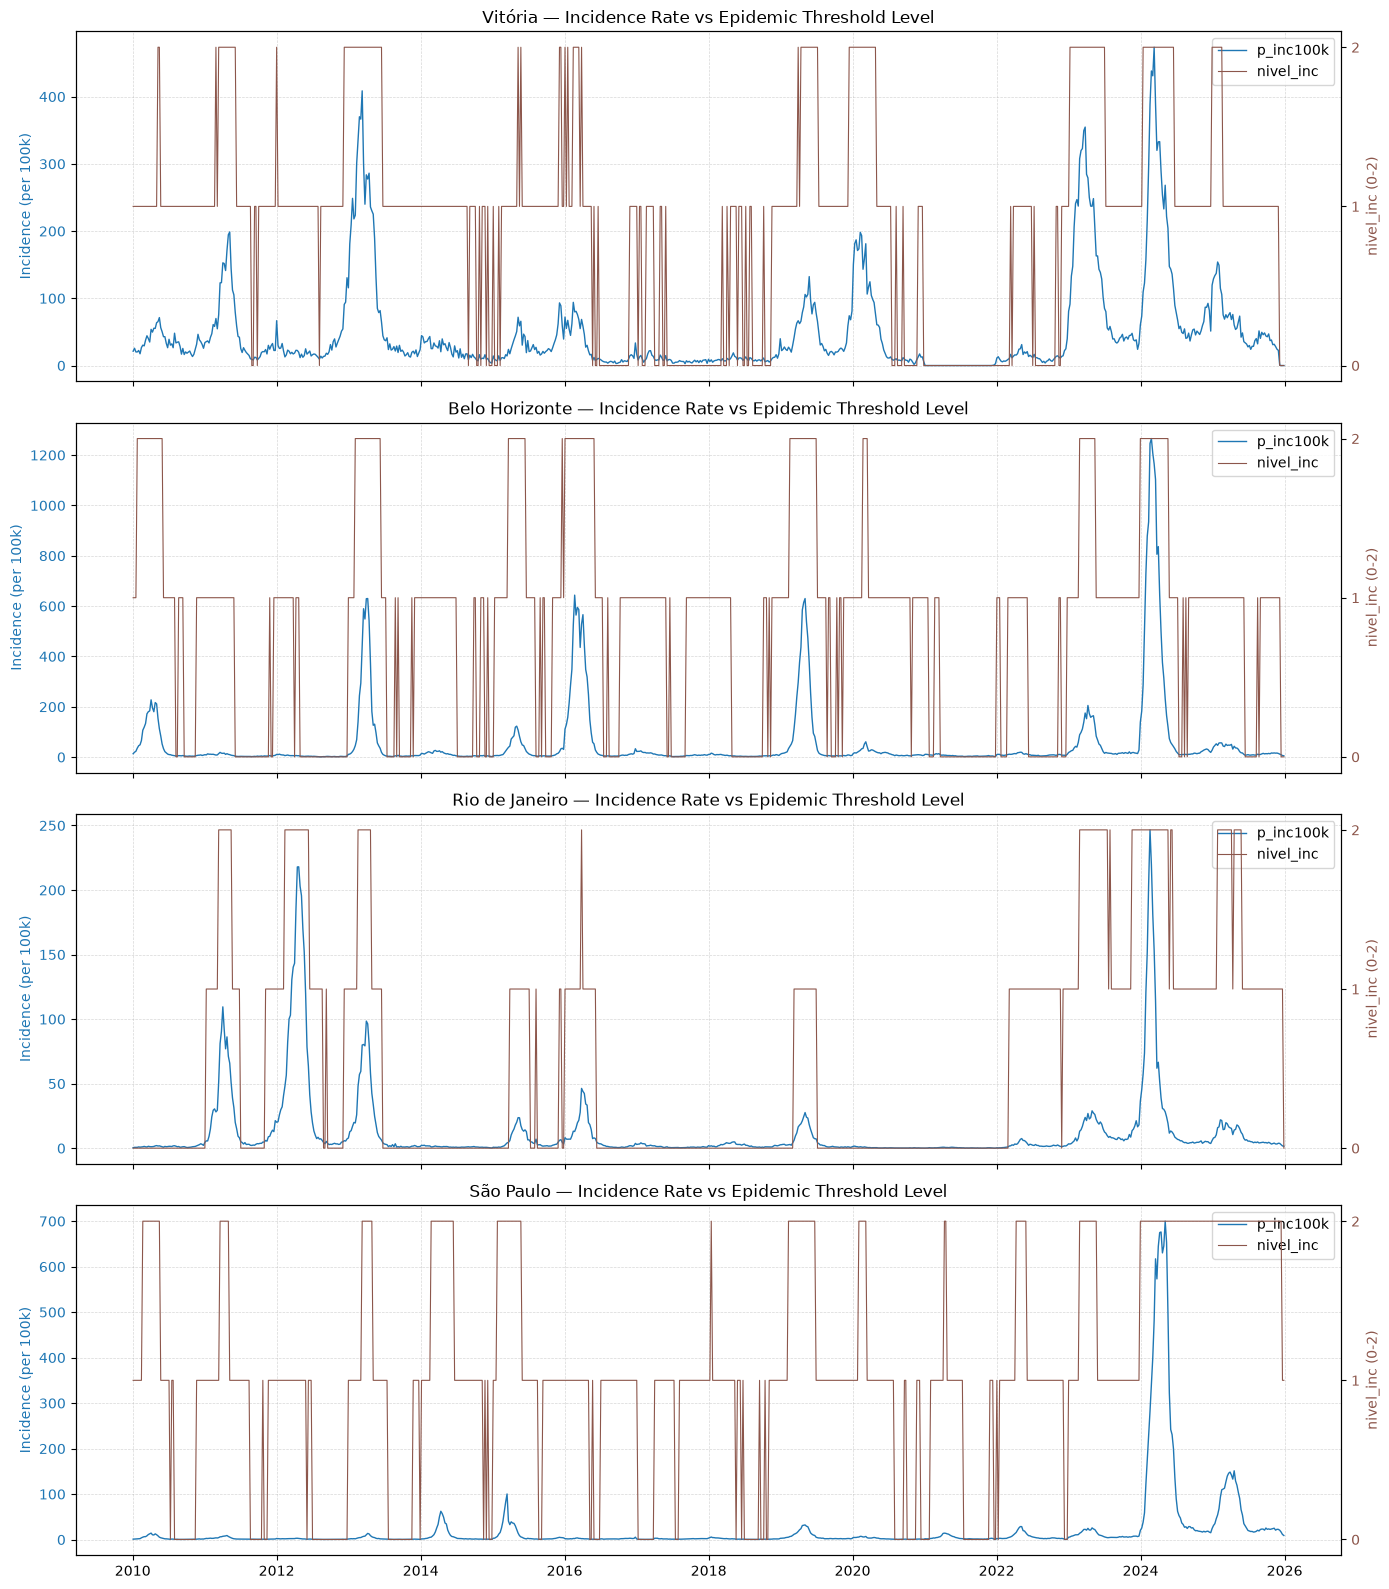

In [12]:
fig, axes = plt.subplots(len(cities), 1, figsize=(14, 4 * len(cities)), sharex=True)

for ax, city in zip(axes, cities):
    city_df = df[df["city_name"] == city].sort_values("data_iniSE")

    
    # Left y-axis: incidence rate
    color_inc = "tab:blue"
    ax.plot(city_df["data_iniSE"], city_df["p_inc100k"], color=color_inc, linewidth=1.0, label="p_inc100k")
    ax.set_ylabel("Incidence (per 100k)", color=color_inc)
    ax.tick_params(axis="y", labelcolor=color_inc)
    ax.set_title(f"{city} — Incidence Rate vs Epidemic Threshold Level")
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.5)
    
    # Right y-axis: nivel_inc
    ax2 = ax.twinx()
    ax2.plot(city_df["data_iniSE"], city_df["nivel_inc"], color="tab:brown", linewidth=0.8, label="nivel_inc")
    ax2.set_ylabel("nivel_inc (0-2)", color="tab:brown")
    ax2.tick_params(axis="y", labelcolor="tab:brown")
    ax2.set_yticks([0, 1, 2])
    
    # Combined legend
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.xlabel("Date")
plt.tight_layout()
plt.show()